In [29]:
# MobileNetV2 extracts visual features from the image.
# The Dense layer receives those features and predicts probabilities for the four classes.
# The loss function measures how far the prediction is from the correct label.
# Backpropagation updates the trainable classification-head weights.
# The frozen MobileNetV2 weights stay unchanged.

In [ ]:
import time
import json
import mlflow

In [ ]:
# ml flow setup


import mlflow

mlflow.set_tracking_uri("https://height-biz-pike-smile.trycloudflare.com")

mlflow.set_experiment("NeuroVision_AI")

experiment = mlflow.get_experiment_by_name("NeuroVision_AI")


In [31]:
from tensorflow.keras.applications import MobileNetV2

In [32]:
# checkpoints folder
CHECKPOINT_DIR = "/home/user/Sync/backup/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

In [33]:
# Model Architecture

def create_tumor_classifier():

    # define the input layer
    inputs = layers.Input(
        shape = (224,224,3),
        name = "mri_images"
    )
    
    # rescaling the images to -1 , 1 for MobileNetV2 (we can use process_input())
    # x new = 2 * x old - 1
    x = layers.Rescaling(
        scale = 2.0,
        offset = -1.0,
        name = 'mobilenet_preprocessing'
    )(inputs)

    #loading the pretrained MobileNetV2
    base_model = MobileNetV2( weights ='imagenet', include_top = False, input_shape =(224, 224, 3))

    # freeze the pretrained layers
    base_model.trainable = False

    # extract images features
    x = base_model(x, training=False)


    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    
    outputs = layers.Dense(4, activation='softmax', name='Classification')(x)

    # Assemble the model

    model = Model(
        inputs = inputs,
        outputs = outputs
    )

    return model, base_model




In [34]:
model, base_model = create_tumor_classifier()

model.summary()

base_model.summary()



9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mri_images (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Classification (Dense)          │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

...

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [35]:
# compile the model 

model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate =0.001 ), # Adam: updates the trainable weights.
    loss= 'categorical_crossentropy',
    metrics = ['accuracy']
)


In [36]:
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(CHECKPOINT_DIR, 'mobilenetv2_best.keras'),
    monitor = 'val_loss',
    save_best_only = True,
    mode = 'min',
    verbose = 1
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience = 3,
    restore_best_weights = True,
    verbose = 1
)


In [ ]:
#training with tracking with mlflow
EPOCHS = 15
BATCH_SIZE = 32

with mlflow.start_run(run_name="MobileNetV2_Transfer_Learning"):

    # Track main parameters
    mlflow.log_param("epochs", EPOCHS)
    mlflow.log_param("batch_size", BATCH_SIZE)

start_time = time.time()

history = model.fit(
    train_dataset,
    validation_data = val_dataset,
    epochs = EPOCHS,
    callbacks = [
        checkpoint_callback,
        early_stopping_callback
    ]
)

# Track training duration
mlflow.log_metric("training_time_seconds", time.time() - start_time)

# Track training history (loss and accuracy for each epoch)
for epoch, metrics in enumerate(
        zip(
            history.history["loss"],
            history.history["accuracy"],
            history.history["val_loss"],
            history.history["val_accuracy"]
        ),
        start=1
    ):
        loss, accuracy, val_loss, val_accuracy = metrics

        mlflow.log_metrics({
            "loss": loss,
            "accuracy": accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        }, step=epoch)

    # Track best validation results
mlflow.log_metric(
        "best_val_accuracy",
        max(history.history["val_accuracy"])
    )
mlflow.log_metric(
        "best_val_loss",
        min(history.history["val_loss"])
    )

Epoch 1/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6467 - loss: 0.8739
Epoch 1: val_loss improved from inf to 0.35647, saving model to /home/user/Sync/backup/checkpoints/mobilenetv2_best.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 22s 76ms/step - accuracy: 0.6474 - loss: 0.8724 - val_accuracy: 0.8675 - val_loss: 0.3565
Epoch 2/20
175/176 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8675 - loss: 0.3695
Epoch 2: val_loss improved from 0.35647 to 0.29810, saving model to /home/user/Sync/backup/checkpoints/mobilenetv2_best.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.8676 - loss: 0.3693 - val_accuracy: 0.8818 - val_loss: 0.2981
Epoch 3/20
173/176 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8814 - loss: 0.3084
Epoch 3: val_loss improved from 0.29810 to 0.26589, saving model to /home/user/Sync/backup/checkpoints/mobilenetv2_best.keras
176/176 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.8816 - loss: 0.3080 - val_accuracy: 0.8960 - val_loss: 0.2659
Epoch 4/20

In [45]:
ARTIFACTS_DIR = "/home/user/Sync/backup/artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

with open(os.path.join(ARTIFACTS_DIR,"transfer_learning_history.json"), "w") as f:
    json.dump(history.history, f)

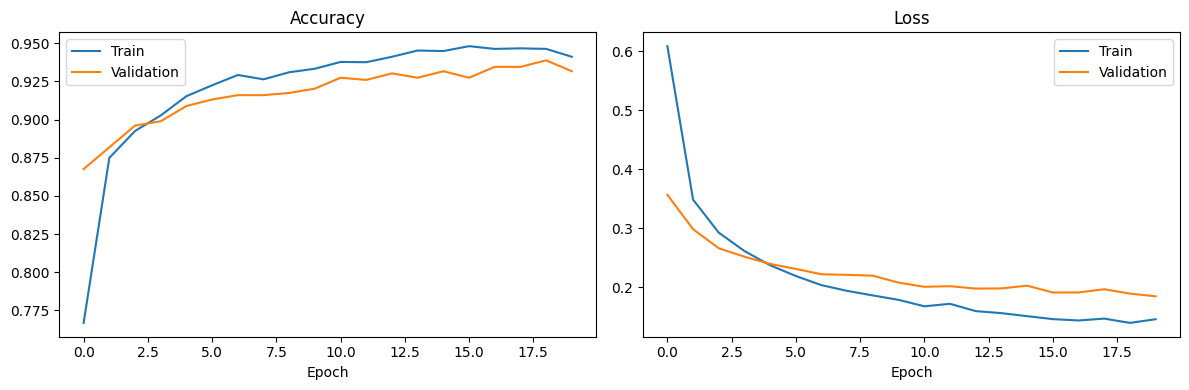

In [38]:
# plotting the history


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()